# Prévision de la demande : méthode, comparaison et limites

Document d'analyse prévu par le cahier des charges (section 8.4) pour la prévision du volume hebdomadaire de demandes
par spécialité sur 4 semaines (EF-24). Il est **reproductible** : il lit la base désignée par `DATABASE_URL` et réutilise
le code du module `backend/analytique/prevision.py` que l'application appelle.

Pour le rejouer : `jupyter nbconvert --to notebook --execute --inplace notebooks/analyse_prevision_demande.ipynb`
(avec `DATABASE_URL` pointant vers la base ; `jupyter` et `matplotlib` ne servent qu'à ce document).

**Les chiffres du texte sont ceux de l'exécution enregistrée ; relancez le document pour obtenir ceux de votre base.**

In [1]:
import sys, warnings
from collections import Counter, defaultdict
from datetime import timedelta
from pathlib import Path
racine = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").is_dir())
sys.path.insert(0, str(racine)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import select

from backend.database import SessionLocale
from backend.models import JourFerie, Medecin, RendezVous, StatutRdv
from backend.analytique.prevision import (METHODES, Serie, choisir_methode, evaluer_serie, intervalle,
                                          jours_ouvres_de_la_semaine, lundi_de)
from backend.planning import aujourdhui

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
VERT, GRIS, ORANGE = "#1b6b4a", "#8a8f98", "#d98c1f"

with SessionLocale() as db:
    lignes = db.execute(select(RendezVous.debut, Medecin.specialite).join(Medecin, RendezVous.medecin_id == Medecin.id)
                        .where(RendezVous.statut != StatutRdv.ANNULE)).all()
    feries = set(db.scalars(select(JourFerie.jour)).all())
lundi_courant = lundi_de(aujourdhui())
passe = defaultdict(Counter)
for debut, spec in lignes:
    if lundi_de(debut.date()) < lundi_courant:
        passe[spec][lundi_de(debut.date())] += 1
premier = min(min(c) for c in passe.values())
semaines = [premier + timedelta(weeks=i) for i in range((lundi_courant - premier).days // 7)]
ouvres = np.array([jours_ouvres_de_la_semaine(s, feries) for s in semaines])
futurs = [lundi_courant + timedelta(weeks=i) for i in range(4)]
ouvres_futurs = np.array([jours_ouvres_de_la_semaine(s, feries) for s in futurs])
print(f"{len(lignes)} rendez-vous non annulés ; {len(semaines)} semaines d'historique ({semaines[0]} à {semaines[-1]}) ; {len(passe)} spécialités")

6930 rendez-vous non annulés ; 52 semaines d'historique (2025-10-13 à 2026-10-05) ; 9 spécialités


## 1. Ce que l'on prévoit

Pour chaque spécialité, le **nombre de rendez-vous par semaine** (du lundi au samedi), annulations exclues. L'horizon est de
4 semaines. Les semaines comportent un nombre variable de jours ouvrés (jours fériés, fermetures), ce que les modèles doivent
savoir : une semaine à 5 jours ouvrés porte moins de rendez-vous qu'une semaine à 6.

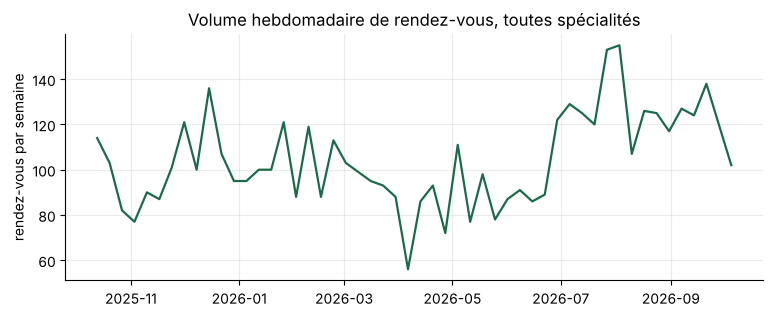

,min,médiane,max
semaine,56.0,100.0,155.0


In [2]:
total = np.array([sum(passe[s][w] for s in passe) for w in semaines], dtype=float)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(semaines, total, color=VERT, lw=1.6)
ax.set_title("Volume hebdomadaire de rendez-vous, toutes spécialités"); ax.set_ylabel("rendez-vous par semaine")
plt.show()
pd.DataFrame({"min": [total.min()], "médiane": [np.median(total)], "max": [total.max()]}, index=["semaine"]).round(0)

## 2. Trois méthodes, du plus simple au plus riche

| Méthode | Idée | Pourquoi la tester |
|---|---|---|
| Moyenne mobile (4 semaines) | la semaine prochaine ressemble à la moyenne des 4 dernières | **référence naïve** : tout modèle plus complexe doit la battre |
| Lissage de Holt (tendance amortie) | niveau et tendance mis à jour semaine après semaine | suit une hausse ou une baisse progressive |
| Régression calendaire | volume expliqué par le nombre de jours ouvrés et la saison | tient compte des semaines raccourcies et des cycles annuels |

Chaque méthode est jugée sur les **8 dernières semaines, tenues à l'écart de l'apprentissage** : on prévoit ces semaines sans les
avoir vues, puis on compare au réel. C'est la seule manière honnête de mesurer une prévision (on ne juge pas un modèle sur
les données qui l'ont ajusté).

In [3]:
serie_de = lambda nom: Serie(nom, semaines, np.array([passe[nom][s] for s in semaines], dtype=float), ouvres)
resultats = {nom: evaluer_serie(serie_de(nom), futurs, ouvres_futurs) for nom in sorted(passe)}
retenue, totaux = choisir_methode(list(resultats.values()))
tableau = pd.DataFrame({METHODES[m]: {"erreur absolue moyenne (rdv/semaine)": totaux[m]["mae"], "erreur relative moyenne (%)": totaux[m]["mape"]} for m in METHODES}).T.round(2)
print("Méthode retenue (erreur absolue la plus faible, toutes spécialités) :", METHODES[retenue])
tableau

Méthode retenue (erreur absolue la plus faible, toutes spécialités) : Régression sur variables calendaires


,erreur absolue moyenne (rdv/semaine),erreur relative moyenne (%)
Moyenne mobile sur 4 semaines (référence naïve),2.74,26.99
Lissage exponentiel de Holt (tendance amortie),2.92,27.54
Régression sur variables calendaires,2.70,24.57


**Lecture.** L'erreur absolue moyenne se lit directement : « en moyenne, la prévision s'écarte de X rendez-vous par semaine
et par spécialité ». Si une méthode sophistiquée ne fait pas mieux que la moyenne mobile, c'est la moyenne mobile qu'il faut
garder : un modèle plus complexe sans gain est un risque, pas un progrès.

**Sur l'exécution enregistrée, le constat est sobre** : la régression calendaire est retenue, mais son erreur (2,70 rendez-vous par
semaine) n'est inférieure que d'environ 1 % à celle de la moyenne mobile (2,74). Autrement dit, sur ces données les trois méthodes
sont pratiquement équivalentes ; le gain ne justifie pas à lui seul de présenter le modèle comme « meilleur ». L'intérêt de
la comparaison est surtout de **le démontrer** et de continuer à le vérifier quand les données réelles arriveront : si l'écart
reste nul, la moyenne mobile suffit.

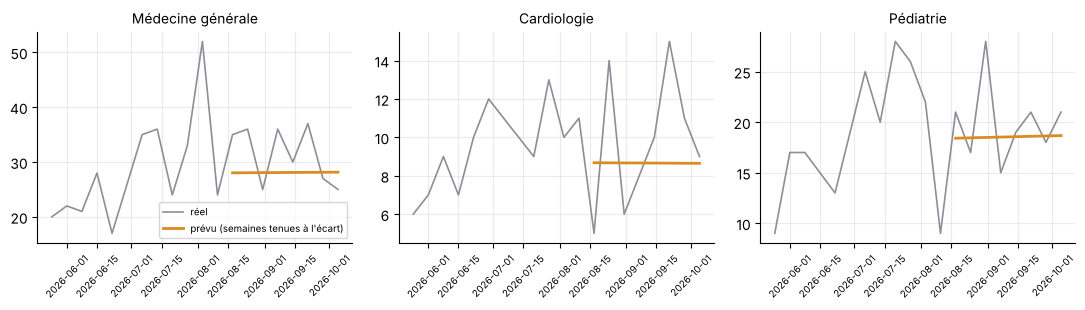

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=False)
for ax, nom in zip(axes, ["Médecine générale", "Cardiologie", "Pédiatrie"]):
    if nom not in resultats:
        ax.set_visible(False); continue
    r = resultats[nom]; ev = r.evaluation[retenue]; n_test = len(ev["reel"])
    ax.plot(r.serie.semaines[-n_test - 12:], r.serie.valeurs[-n_test - 12:], color=GRIS, lw=1.2, label="réel")
    ax.plot(r.serie.semaines[-n_test:], ev["prevu"], color=ORANGE, lw=2, label="prévu (semaines tenues à l'écart)")
    ax.set_title(nom, fontsize=10); ax.tick_params(axis="x", rotation=45, labelsize=7)
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 3. Les 4 semaines à venir

La prévision est donnée avec un **intervalle d'environ 90 %** : prévision ± 1,645 écart-type, où l'écart-type est l'erreur
quadratique observée sur les semaines tenues à l'écart (avec un plancher de Poisson, qui rappelle qu'un comptage a toujours
une variabilité propre). L'application affiche aussi, pour chaque semaine, le nombre de rendez-vous **déjà pris** : le volume
final ne peut pas être inférieur à ce nombre.

In [5]:
lignes_prev = []
for nom, r in resultats.items():
    prev = r.futures[retenue]; bas, haut = intervalle(r, retenue, prev)
    for i, lundi in enumerate(futurs):
        lignes_prev.append({"spécialité": nom, "semaine du": lundi, "prévision": round(float(prev[i]), 1), "bas": round(float(bas[i]), 1), "haut": round(float(haut[i]), 1)})
prev_df = pd.DataFrame(lignes_prev)
prev_df.pivot_table(index="spécialité", columns="semaine du", values="prévision").round(1)

semaine du,2026-10-12,2026-10-19,2026-10-26,2026-11-02
spécialité,,,,
Cardiologie,9.3,9.3,9.3,9.3
Dermatologie,9.2,9.2,9.3,9.3
Endocrinologie,8.2,8.2,8.2,8.2
Gynécologie-obstétrique,19.4,19.6,19.7,19.8
Kinésithérapie,6.2,6.2,6.3,6.3
Médecine générale,29.9,30.0,30.0,30.1
ORL,7.4,7.4,7.5,7.5
Ophtalmologie,11.4,11.5,11.5,11.6
Pédiatrie,19.5,19.6,19.6,19.7


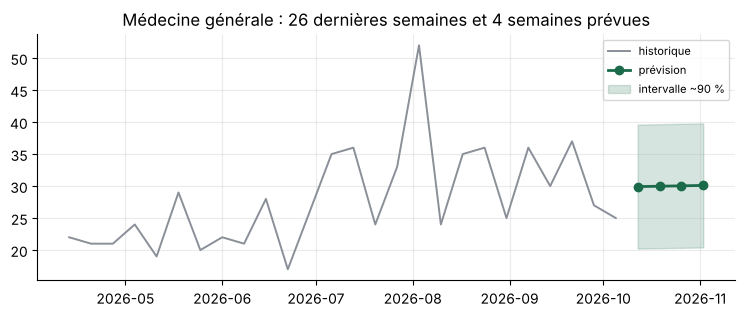

In [6]:
nom = max(resultats, key=lambda n: resultats[n].serie.valeurs.mean())
r = resultats[nom]; prev = r.futures[retenue]; bas, haut = intervalle(r, retenue, prev)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(r.serie.semaines[-26:], r.serie.valeurs[-26:], color=GRIS, lw=1.4, label="historique")
ax.plot(futurs, prev, color=VERT, lw=2, marker="o", label="prévision")
ax.fill_between(futurs, bas, haut, color=VERT, alpha=0.18, label="intervalle ~90 %")
ax.set_title(f"{nom} : 26 dernières semaines et 4 semaines prévues"); ax.legend(fontsize=8); plt.show()

## 4. Limites

- **Données synthétiques.** Les chiffres de ce document viennent d'un jeu de démonstration : ils illustrent la démarche et
  ne préjugent pas de la précision sur les données réelles de la clinique.
- **Historique court.** Environ une année : la saisonnalité annuelle ne peut être estimée qu'à partir d'un seul cycle.
- **Événements non modélisés.** Campagne de santé, épidémie, grève, travaux : une prévision issue du seul historique ne les voit pas.
- **Séries à faible volume.** Pour les petites spécialités, l'erreur relative est mécaniquement élevée : un écart de 2 rendez-vous
  sur 6 pèse 33 %. L'erreur absolue est plus parlante.
- **Usage.** La prévision aide à dimensionner les plages ouvertes ; elle ne remplace pas le jugement du responsable des opérations.

## 5. Conclusion

La comparaison sur des semaines cachées permet de choisir la méthode sur des faits. L'application la recalcule à chaque
consultation avec les données de la base ; dès que l'historique réel sera chargé, relancer ce document dira si le choix tient.